# Year-by-year removal-target snapshots (2050-2100)

Standalone notebook (no dependency on other notebooks). `removal_target_comparison.ipynb`
finds the lowest-cost system for a single *cumulative* 2050-2100 removal target -- but
because that model holds capacity (and therefore annual capture rate) constant for the
whole 50-year window, the system it finds is mathematically equivalent to the *average*
annual rate of the target. For the linear pathways in Energy Journal Fig. 3, that average
equals the pathway's value at the midpoint year, 2075 -- not any specific year's real
requirement.

This notebook removes that averaging: for each of 2050, 2060, 2070, 2080, 2090 and 2100,
it finds the lowest-cost `(renewables_gw, e_dac_capacity_gw)` system that hits the
*instantaneous annual removal rate* Fig. 3's blue pathway (natural continuation of the
modelled 2023-2050 gradient) and purple pathway (steeper, backward-solved so its own
2050-2100 cumulative total is 5.76 GtCO2e) prescribe at that year. 2050 is a single target
(both pathways start at the same point); 2060-2100 each carry two targets (blue and
purple), drawn together on one contour plot exactly as `removal_target_comparison.ipynb`
already overlays two targets on one plot -- so this notebook produces 6 figures in total.

The blue/purple target values are computed inline below using the same formulas as
`nbs/Energy Journal.ipynb` (`extension_gradient`, `third_gradient`), so the two notebooks
are guaranteed consistent by construction even though neither imports the other.

In [1]:
from __future__ import annotations

import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src.assumptions as A
import src.matplotlib_style  # noqa: F401
from src.data import renewable_capacity_factors
from src.demand_model import DemandMode, predicted_demand
from src.power_system import PowerSystem
from src.supply_model import daily_renewables_capacity
from src.units import Units as U

In [2]:
CAPACITY_FACTORS_SOURCE = "era5_2024"
DEMAND_MODE = DemandMode.SEASONAL
ENABLE_IMPORTS = False

HYDROGEN_STORAGE_TWH = A.HydrogenStorage.CavernStorage.Capacity
ELECTROLYSER_GW = A.HydrogenStorage.Electrolysis.Power
HYDROGEN_GEN_GW = A.HydrogenStorage.Generation.Power

demand_df = predicted_demand(mode=DEMAND_MODE, historical="era5", filter_ldz=True)
daily_cf = renewable_capacity_factors.get_renewable_capacity_factors(
    source=CAPACITY_FACTORS_SOURCE,
    resample="D",
)


def build_net_supply_df(ren_gw: float) -> pd.DataFrame:
    supply = daily_renewables_capacity(ren_gw * U.GW, daily_cf)
    common_idx = supply.index.intersection(demand_df.index)
    supply = supply.reindex(common_idx)
    demand = demand_df.reindex(common_idx)
    net_supply_df = (supply - demand["demand"]).to_frame(name=f"S-D(TWh),Ren={ren_gw}GW")
    net_supply_df = net_supply_df.reset_index()
    net_supply_df = net_supply_df.rename(columns={net_supply_df.columns[0]: "index"})
    return net_supply_df


def run_scenario(ren_gw: float, dac_gw: float) -> tuple[PowerSystem, pd.DataFrame | None, dict | None]:
    net_supply_df = build_net_supply_df(ren_gw)
    system = PowerSystem(
        renewable_capacity=ren_gw * U.GW,
        hydrogen_storage_capacity=HYDROGEN_STORAGE_TWH,
        electrolyser_power=ELECTROLYSER_GW,
        dac_capacity=dac_gw * U.GW,
        hydrogen_generation_power=HYDROGEN_GEN_GW,
        enable_imports=ENABLE_IMPORTS,
        capacity_factors_source=CAPACITY_FACTORS_SOURCE,
        enable_gas_ltdac=True,
    )
    sim_df = system.run_simulation(net_supply_df)
    analysis = system.analyze_simulation_results(sim_df)
    return system, sim_df, analysis


def evaluate_scenario(renewables_gw: float, edac_capacity_gw: float) -> dict | None:
    system, sim_df, analysis = run_scenario(renewables_gw, edac_capacity_gw)

    if analysis is None:
        return None

    annual_net_capture_mt = analysis["annual_net_capture"].to(U.Mt).magnitude

    power_system_cost_gbp_yr = system.calculate_power_system_cost(sim_df).to(U.GBP).magnitude
    dac_cost_gbp_yr = analysis["annual_dac_total_cost"].to(U.GBP).magnitude
    total_cost_gbp_yr = power_system_cost_gbp_yr + dac_cost_gbp_yr

    return {
        "renewables_gw": renewables_gw,
        "e_dac_capacity_gw": edac_capacity_gw,
        "annual_net_capture_mtco2_yr": annual_net_capture_mt,
        "dac_cost_gbp_yr": dac_cost_gbp_yr,
        "power_system_cost_gbp_yr": power_system_cost_gbp_yr,
        "total_cost_gbp_yr": total_cost_gbp_yr,
    }

In [3]:
# Same derivation as nbs/Energy Journal.ipynb's `extension_gradient` (blue) and
# `third_gradient` (purple) cells -- reproduced inline here (rather than
# imported) so this notebook stays standalone/self-executing, while remaining
# numerically identical by construction.
extension_start_year = 2050
extension_end_year = 2100
extension_start_value = -35.82  # MtCO2e/yr: CB7 2050 engineered-removal rate

pathway_start_year = 2028
pathway_end_value = abs(extension_start_value)
pathway_slope = pathway_end_value / (extension_start_year - pathway_start_year)
extension_gradient = -pathway_slope  # blue pathway: natural continuation of 2023-2050 trend

third_target_area = -5761  # MtCO2e: purple pathway's own 2050-2100 cumulative total (5.761 Gt)
third_end_value = (
    2 * third_target_area / (extension_end_year - extension_start_year) - extension_start_value
)
third_gradient = (third_end_value - extension_start_value) / (
    extension_end_year - extension_start_year
)


def slope_value_at(year: float) -> float:
    return extension_start_value + extension_gradient * (year - extension_start_year)


def third_value_at(year: float) -> float:
    return extension_start_value + third_gradient * (year - extension_start_year)


SNAPSHOT_YEARS = [2050, 2060, 2070, 2080, 2090, 2100]

# Each year maps to a TARGET_SPECS-shaped list: (target_mt_per_yr, label, color, linestyle).
# 2050 has one shared target; 2060-2100 each carry a Linear and an Extended
# target. Linear is drawn in white (rather than its previous black, which
# blended into the contour plots' dark-blue/dark-red `turbo` bands) with a
# thin black outline wherever it's plotted (see `_outline_effect` in the
# plotting cells below) so it also stays visible against the light-yellow/
# green band; Extended moved from purple to plain black, which needs no
# outline since black already reads clearly across the whole colormap.
YEAR_GROUPS: dict[int, list[tuple[float, str, str, str]]] = {
    2050: [(abs(slope_value_at(2050)), "2050", "dimgray", "--")],
}
for year in SNAPSHOT_YEARS[1:]:
    YEAR_GROUPS[year] = [
        (abs(slope_value_at(year)), f"{year} (Linear)", "white", ":"),
        (abs(third_value_at(year)), f"{year} (Extended)", "black", "-."),
    ]

for year, specs in YEAR_GROUPS.items():
    print(year, [(round(v, 2), label) for v, label, _, _ in specs])

2050 [(35.82, '2050')]
2060 [(52.1, '2060 (Linear)'), (67.58, '2060 (Extended)')]
2070 [(68.38, '2070 (Linear)'), (99.34, '2070 (Extended)')]
2080 [(84.67, '2080 (Linear)'), (131.1, '2080 (Extended)')]
2090 [(100.95, '2090 (Linear)'), (162.86, '2090 (Extended)')]
2100 [(117.23, '2100 (Linear)'), (194.62, '2100 (Extended)')]


In [4]:
# Coarse, wide-range pre-scan: locates roughly where each year group's
# optimal points sit, so the fine grid below can be sized to bracket all of
# them without guessing. Mirrors the "coarser range search beforehand"
# approach documented in removal_target_comparison.ipynb, just over a much
# wider range -- these targets span 35.8-194.6 MtCO2/yr of *instantaneous*
# annual rate, versus that notebook's 76-115 MtCO2/yr *cumulative average*.
COARSE_REN_VALUES = np.arange(0, 450.01, 10)
COARSE_EDAC_VALUES = np.arange(0, 150.01, 5)

coarse_rows = [
    row
    for renewables_gw in COARSE_REN_VALUES
    for edac_capacity_gw in COARSE_EDAC_VALUES
    if (row := evaluate_scenario(float(renewables_gw), float(edac_capacity_gw))) is not None
]
coarse_table = pd.DataFrame(coarse_rows)

print(
    f"Coarse grid: {len(coarse_table)} scenarios "
    f"({len(COARSE_REN_VALUES)} renewables x {len(COARSE_EDAC_VALUES)} E-DAC)"
)
print(coarse_table["annual_net_capture_mtco2_yr"].describe())

F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: RuntimeWarning: invalid value encountered in scalar divide
  magnitude = magnitude_op(new_self._magnitude, other._magnitude)
F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: RuntimeWarning: invalid value encountered in scalar divide
  magnitude = magnitude_op(new_self._magnitude, other._magnitude)
F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: RuntimeWarning: invalid value encountered in scalar divide
  magnitude = magnitude_op(new_self._magnitude, other._magnitude)
F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: RuntimeWarning: invalid value encountered in scalar divide
  magnitude = magnitude_op(new_self._magnitude, other._magnitude)
F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: Runti

Coarse grid: 837 scenarios (46 renewables x 31 E-DAC)
count     837.000000
mean      494.171919
std       338.571231
min         0.227878
25%       208.792912
50%       445.497426
75%       747.446452
max      1335.166438
Name: annual_net_capture_mtco2_yr, dtype: float64


In [5]:
# For each target, the three "optimal point" rows (lowest cost / lowest
# renewables / lowest E-DAC) that the final plots will mark -- found here on
# the coarse grid just to bound the fine grid, and recomputed properly on the
# fine grid for the actual plots.
def optimal_points(df: pd.DataFrame, target_mt_per_yr: float) -> list[pd.Series]:
    meeting = df[df["annual_net_capture_mtco2_yr"] >= target_mt_per_yr]
    if meeting.empty:
        return []
    return [
        meeting.sort_values(["total_cost_gbp_yr", "renewables_gw", "e_dac_capacity_gw"]).iloc[0],
        meeting.sort_values(["renewables_gw", "e_dac_capacity_gw", "total_cost_gbp_yr"]).iloc[0],
        meeting.sort_values(["e_dac_capacity_gw", "renewables_gw", "total_cost_gbp_yr"]).iloc[0],
    ]


all_targets = [spec[0] for specs in YEAR_GROUPS.values() for spec in specs]

coarse_points = []
missed_targets = []
for target in all_targets:
    points = optimal_points(coarse_table, target)
    if not points:
        missed_targets.append(target)
    coarse_points.extend(points)

if missed_targets:
    raise RuntimeError(
        f"No coarse-grid scenario meets targets {missed_targets} MtCO2/yr -- "
        "widen COARSE_REN_VALUES/COARSE_EDAC_VALUES above."
    )

ren_hits = [p["renewables_gw"] for p in coarse_points]
edac_hits = [p["e_dac_capacity_gw"] for p in coarse_points]

edac_pad = max(10.0, (max(edac_hits) - min(edac_hits)) * 0.3)

# Renewable capacity conceptually starts at 0 -- always include that origin
# in the fine grid (rather than a padded value above it) so every plot's
# x-axis can show the *complete* picture down to 0 GW installed renewables,
# including the infeasible region below wherever a target's true asymptote
# sits, instead of only the narrow neighbourhood around the optimal points.
FINE_REN_MIN = 0.0
FINE_REN_MAX = max(ren_hits) + max(20.0, (max(ren_hits) - min(ren_hits)) * 0.3)
FINE_EDAC_MIN = max(0.0, min(edac_hits) - edac_pad)
FINE_EDAC_MAX = max(edac_hits) + edac_pad

print(
    f"Fine grid bounds: renewables {FINE_REN_MIN:.0f}-{FINE_REN_MAX:.0f} GW, "
    f"E-DAC {FINE_EDAC_MIN:.0f}-{FINE_EDAC_MAX:.0f} GW"
)

Fine grid bounds: renewables 0-489 GW, E-DAC 0-57 GW


In [6]:
# Single shared fine grid covering all 6 year groups -- built once and
# reused (sliced/zoomed) by every plot below, rather than re-searching per
# target. Step size auto-coarsens to keep the total evaluation count (and
# runtime) bounded regardless of how wide the bounding box above turns out
# to be.
MAX_FINE_EVALUATIONS = 20_000
FINE_STEP_GW = 1.0

while True:
    n_ren = int((FINE_REN_MAX - FINE_REN_MIN) / FINE_STEP_GW) + 1
    n_edac = int((FINE_EDAC_MAX - FINE_EDAC_MIN) / FINE_STEP_GW) + 1
    if n_ren * n_edac <= MAX_FINE_EVALUATIONS:
        break
    FINE_STEP_GW += 0.5

FINE_REN_VALUES = np.arange(FINE_REN_MIN, FINE_REN_MAX + FINE_STEP_GW / 2, FINE_STEP_GW)
FINE_EDAC_VALUES = np.arange(FINE_EDAC_MIN, FINE_EDAC_MAX + FINE_STEP_GW / 2, FINE_STEP_GW)

fine_rows = [
    row
    for renewables_gw in FINE_REN_VALUES
    for edac_capacity_gw in FINE_EDAC_VALUES
    if (row := evaluate_scenario(float(renewables_gw), float(edac_capacity_gw))) is not None
]
grid_table = pd.DataFrame(fine_rows)

print(
    f"Fine grid: {len(grid_table)} scenarios "
    f"({len(FINE_REN_VALUES)} renewables x {len(FINE_EDAC_VALUES)} E-DAC, step={FINE_STEP_GW:.1f} GW)"
)

F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: RuntimeWarning: invalid value encountered in scalar divide
  magnitude = magnitude_op(new_self._magnitude, other._magnitude)
F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: RuntimeWarning: invalid value encountered in scalar divide
  magnitude = magnitude_op(new_self._magnitude, other._magnitude)
F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: RuntimeWarning: invalid value encountered in scalar divide
  magnitude = magnitude_op(new_self._magnitude, other._magnitude)
F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: RuntimeWarning: invalid value encountered in scalar divide
  magnitude = magnitude_op(new_self._magnitude, other._magnitude)
F:\UK-Energy-Modelling-Update-main-web\.venv\Lib\site-packages\pint\facets\plain\quantity.py:1029: Runti

Fine grid: 7800 scenarios (327 renewables x 39 E-DAC, step=1.5 GW)


In [7]:
# Reusable plotting function -- refactored from removal_target_comparison.ipynb's
# `comparison-plot` cell, which already loops over an N-entry target-specs list
# on one shared contour. Differences here: the underlying metric is the
# *instantaneous* annual capture rate (not a 2050-2100 cumulative total).
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.transforms import Bbox

METRIC_COL = "annual_net_capture_mtco2_yr"

POINT_TYPE_MARKER = {"Lowest cost": "o"}
POINT_TYPE_FACECOLOR = {"Lowest cost": "white"}
COLOR_CMAP = "turbo"


def _outline_effect(color: str) -> list:
    """A thin black stroke behind anything drawn in "white" -- otherwise a
    plain white line/marker/legend swatch can nearly vanish against this
    notebook's `turbo` colormap's light-yellow/green band (and against a
    white legend background). No-op for every other color.
    """
    return [pe.withStroke(linewidth=3, foreground="black")] if color == "white" else []


# One shared color scale across all 6 plots (rather than rescaling per target)
# so color is directly comparable year-to-year: the same MtCO2/yr rate maps to
# the same color everywhere. Dense levels cover 0 up to just above the
# highest of all 11 target values (2100 purple, ~194.6), coarser levels fade
# out further beyond that -- anything past GLOBAL_VMAX_FADE still gets the
# top color via contourf's "extend" arrow.
ALL_TARGET_VALUES = [spec[0] for specs in YEAR_GROUPS.values() for spec in specs]
GLOBAL_VMAX_DENSE = max(ALL_TARGET_VALUES) * 1.2
GLOBAL_VMAX_FADE = max(ALL_TARGET_VALUES) * 3.0
GLOBAL_COLOR_LEVELS = np.concatenate(
    [
        np.linspace(0, GLOBAL_VMAX_DENSE, 25),
        np.linspace(GLOBAL_VMAX_DENSE, GLOBAL_VMAX_FADE, 13)[1:],
    ]
)

# Pivot the shared fine grid once -- every plot below draws from this same
# (x, y, z) surface, so a single pivot (rather than one per call) is enough.
PLOT_DF = grid_table[
    grid_table["renewables_gw"].notna()
    & grid_table["e_dac_capacity_gw"].notna()
    & grid_table[METRIC_COL].notna()
]
_pivot = PLOT_DF.pivot_table(
    index="e_dac_capacity_gw",
    columns="renewables_gw",
    values=METRIC_COL,
    aggfunc="mean",
)
GRID_X = _pivot.columns.to_numpy(dtype=float)
GRID_Y = _pivot.index.to_numpy(dtype=float)
GRID_Z = _pivot.to_numpy(dtype=float)

# One universal (x, y) window for all 6 plots, so they cover the same area
# and are directly comparable -- rather than each plot zooming to its own
# three marker points. Sized from the *actual* extent of all 11 target
# lines (not just their marker points), so that every line's near-vertical
# segment (E-DAC climbing steeply as renewables fall towards infeasibility)
# and near-horizontal segment (E-DAC levelling off at high renewables) both
# stay visible on every plot.
_scratch_fig, _scratch_ax = plt.subplots()
_line_x, _line_y = [], []
for _specs in YEAR_GROUPS.values():
    for _target_mt_per_yr, _label, _color, _linestyle in _specs:
        if not (PLOT_DF[METRIC_COL] >= _target_mt_per_yr).any():
            continue
        _cs = _scratch_ax.contour(GRID_X, GRID_Y, GRID_Z, levels=[_target_mt_per_yr])
        for _path in _cs.get_paths():
            _line_x.append(_path.vertices[:, 0])
            _line_y.append(_path.vertices[:, 1])
plt.close(_scratch_fig)

_line_x = np.concatenate(_line_x)
_line_y = np.concatenate(_line_y)
_x_pad = (_line_x.max() - _line_x.min()) * 0.08
_y_pad = (_line_y.max() - _line_y.min()) * 0.08

# Left bound pulled back to GRID_X.min() -- the grid's actual leftmost
# renewables value with any valid data. Below this, PowerSystem's
# analyze_simulation_results returns None for every E-DAC level tried
# (the system is infeasible there, not just uncomputed), so 150-185ish GW
# had no data to show and rendered as blank space.
UNIVERSAL_XLIM = (GRID_X.min(), min(GRID_X.max(), _line_x.max() + _x_pad))
UNIVERSAL_YLIM = (max(GRID_Y.min(), _line_y.min() - _y_pad), min(GRID_Y.max(), _line_y.max() + _y_pad))

print(f"Universal window: renewables {UNIVERSAL_XLIM[0]:.0f}-{UNIVERSAL_XLIM[1]:.0f} GW, E-DAC {UNIVERSAL_YLIM[0]:.0f}-{UNIVERSAL_YLIM[1]:.0f} GW")


def plot_target_snapshot(target_specs: list[tuple[float, str, str, str]], title: str):
    x, y, z = GRID_X, GRID_Y, GRID_Z

    candidate_rows = []
    for target_mt_per_yr, label, color, linestyle in target_specs:
        meeting_df = PLOT_DF[PLOT_DF[METRIC_COL] >= target_mt_per_yr]
        if meeting_df.empty:
            print(f"No scenarios meet {target_mt_per_yr:.1f} MtCO2/yr ({label}) in the searched grid.")
            continue

        point_specs = [
            ("Lowest cost", meeting_df.sort_values(["total_cost_gbp_yr", "renewables_gw", "e_dac_capacity_gw"]).iloc[0]),
            ("Lowest renewables", meeting_df.sort_values(["renewables_gw", "e_dac_capacity_gw", "total_cost_gbp_yr"]).iloc[0]),
            ("Lowest E-DAC", meeting_df.sort_values(["e_dac_capacity_gw", "renewables_gw", "total_cost_gbp_yr"]).iloc[0]),
        ]
        for point_type, row in point_specs:
            candidate_rows.append(
                {
                    "renewables_gw": row["renewables_gw"],
                    "e_dac_capacity_gw": row["e_dac_capacity_gw"],
                    "metric_value": row[METRIC_COL],
                    "total_cost_gbp_yr": row["total_cost_gbp_yr"],
                    "dac_cost_gbp_yr": row["dac_cost_gbp_yr"],
                    "target_label": label,
                    "target_color": color,
                    "point_type": point_type,
                }
            )

    fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
    contour = ax.contourf(x, y, z, levels=GLOBAL_COLOR_LEVELS, cmap=COLOR_CMAP, extend="max")
    ax.set_xlim(UNIVERSAL_XLIM)
    ax.set_ylim(UNIVERSAL_YLIM)

    if not candidate_rows:
        print(f"No scenarios meet any target for '{title}'; nothing to plot.")
        colorbar = fig.colorbar(contour, ax=ax)
        colorbar.set_label("Annual net CO2 capture rate (MtCO2/yr)")
        ax.set_title(title, pad=14)
        ax.set_xlabel("Installed renewable capacity (GW)")
        ax.set_ylabel("Installed E-DAC capacity (GW)")
        ax.grid(True, alpha=0.25)
        plt.show()
        return fig, ax, None

    candidates_df = pd.DataFrame(candidate_rows)

    # Target lines carry no inline text label any more (the legend already
    # names each one). Kept per-target (as its contour path's vertices) so
    # the tangent-line block below can use them.
    target_curve_vertices = {}
    for target_mt_per_yr, label, color, linestyle in target_specs:
        if label not in set(candidates_df["target_label"]):
            continue
        cs = ax.contour(x, y, z, levels=[target_mt_per_yr], colors=color, linewidths=2.6, linestyles=linestyle)
        cs.set_path_effects(_outline_effect(color))
        paths = cs.get_paths()
        if paths:
            target_curve_vertices[label] = np.concatenate([p.vertices for p in paths])

    def _tangent_at_extreme(verts: np.ndarray, axis: int, n_neighbors: int = 3):
        """Point + local slope (dy/dx) at the vertex extreme along `axis`
        (0 = leftmost point, 1 = bottommost point), estimated from a small
        neighbourhood of the curve's own vertices around it.
        """
        i0 = int(np.argmin(verts[:, axis]))
        i_lo, i_hi = max(0, i0 - n_neighbors), min(len(verts) - 1, i0 + n_neighbors)
        x0, y0 = verts[i0, 0], verts[i0, 1]
        if i_hi == i_lo:
            return x0, y0, 0.0
        dx = verts[i_hi, 0] - verts[i_lo, 0]
        dy = verts[i_hi, 1] - verts[i_lo, 1]
        return x0, y0, (dy / dx if dx != 0 else np.inf)

    # Tangent lines to the target curve at its global leftmost and
    # bottommost vertices within the searched grid, and the table this
    # function returns (hence the summary table downstream) updated to that
    # same point for "Lowest renewables"/"Lowest E-DAC". Cost figures
    # approximated from the nearest evaluated grid point.
    for target_mt_per_yr, label, color, linestyle in target_specs:
        verts = target_curve_vertices.get(label)
        if verts is None or len(verts) < 2:
            continue
        for axis, point_type in ((0, "Lowest renewables"), (1, "Lowest E-DAC")):
            x0, y0, slope = _tangent_at_extreme(verts, axis)

            # At the grid's own left edge (GRID_X.min()) the curve hasn't
            # actually reached its true leftmost point -- the search just
            # stopped there, so the "tangent" is a grid-boundary artifact,
            # not a real local slope. Skip drawing it (2050 and 2060 hit
            # this; later years' curves settle within the grid).
            at_grid_edge = axis == 0 and np.isclose(x0, GRID_X.min())
            if not at_grid_edge:
                if np.isfinite(slope):
                    x_line = np.array(UNIVERSAL_XLIM)
                    (tangent_line,) = ax.plot(x_line, y0 + slope * (x_line - x0), color=color, linewidth=1.3, alpha=0.65, zorder=6)
                    tangent_line.set_path_effects(_outline_effect(color))
                else:
                    tangent_line = ax.axvline(x0, color=color, linewidth=1.3, alpha=0.65, zorder=6)
                    tangent_line.set_path_effects(_outline_effect(color))

            mask = (candidates_df["target_label"] == label) & (candidates_df["point_type"] == point_type)
            if not mask.any():
                continue
            idx = candidates_df.index[mask][0]
            nearest = PLOT_DF.iloc[
                ((PLOT_DF["renewables_gw"] - x0) ** 2 + (PLOT_DF["e_dac_capacity_gw"] - y0) ** 2).argmin()
            ]
            candidates_df.loc[idx, "renewables_gw"] = x0
            candidates_df.loc[idx, "e_dac_capacity_gw"] = y0
            candidates_df.loc[idx, "metric_value"] = target_mt_per_yr
            candidates_df.loc[idx, "total_cost_gbp_yr"] = nearest["total_cost_gbp_yr"]
            candidates_df.loc[idx, "dac_cost_gbp_yr"] = nearest["dac_cost_gbp_yr"]

    # "Lowest cost" stays a genuine point -- the cheapest system on the curve,
    # not an axis limit -- with its usual annotated box. It's now the only
    # point-type marker, so there's no more "multiple point-types coincide at
    # the same spot" case to merge/handle.
    lowest_cost_rows = candidates_df[candidates_df["point_type"] == "Lowest cost"]

    placed_boxes: list[Bbox] = []
    marker_specs = []

    for _, row in lowest_cost_rows.iterrows():
        xy = (row["renewables_gw"], row["e_dac_capacity_gw"])
        marker = ax.scatter(
            *xy,
            marker=POINT_TYPE_MARKER["Lowest cost"],
            facecolor=POINT_TYPE_FACECOLOR["Lowest cost"],
            edgecolor=row["target_color"],
            s=170,
            linewidth=1.5,
            zorder=7,
        )
        marker.set_path_effects(_outline_effect(row["target_color"]))

        label_text = (
            f"Lowest cost\n"
            f"({row['target_label']})\n"
            f"{row['renewables_gw']:.0f} GW renewables\n"
            f"{row['e_dac_capacity_gw']:.0f} GW E-DAC\n"
            f"{row['metric_value']:.1f} MtCO2/yr\n"
            f"£{row['total_cost_gbp_yr'] / 1e9:.2f}bn/yr total "
            f"(DAC £{row['dac_cost_gbp_yr'] / 1e9:.2f}bn/yr)"
        )
        marker_specs.append((xy, label_text, row["target_color"]))

        marker_px = ax.transData.transform(xy)
        half = 11
        placed_boxes.append(Bbox([[marker_px[0] - half, marker_px[1] - half], [marker_px[0] + half, marker_px[1] + half]]))

    def _padded(bbox: Bbox, pad: float = 6.0) -> Bbox:
        return Bbox([[bbox.x0 - pad, bbox.y0 - pad], [bbox.x1 + pad, bbox.y1 + pad]])

    def _annotation_extent(annotation) -> Bbox:
        patch = annotation.get_bbox_patch()
        if patch is not None:
            return patch.get_window_extent(renderer=renderer)
        return annotation.get_window_extent(renderer=renderer)

    placed_boxes = [_padded(b) for b in placed_boxes]

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    angles = [i * 30 for i in range(12)]

    axes_bounds = ax.get_window_extent(renderer=renderer)

    def _within_axes(bbox: Bbox) -> bool:
        return (
            bbox.x0 >= axes_bounds.x0
            and bbox.x1 <= axes_bounds.x1
            and bbox.y0 >= axes_bounds.y0
            and bbox.y1 <= axes_bounds.y1
        )

    for xy, text, edgecolor in marker_specs:
        chosen_bbox = None
        radius = 20.0
        while chosen_bbox is None and radius <= 160.0:
            for angle in angles:
                rad = math.radians(angle)
                dx, dy = radius * math.cos(rad), radius * math.sin(rad)
                ann = ax.annotate(
                    text, xy=xy, xytext=(dx, dy), textcoords="offset points", fontsize=8,
                    ha="left" if dx >= 0 else "right", va="bottom" if dy >= 0 else "top",
                    bbox={"boxstyle": "round,pad=0.35", "facecolor": "white", "edgecolor": edgecolor, "alpha": 1.0, "linewidth": 1.1},
                    arrowprops={"arrowstyle": "-", "color": edgecolor, "linewidth": 0.9, "shrinkA": 0, "shrinkB": 5},
                    zorder=8,
                )
                fig.canvas.draw()
                bbox = _padded(_annotation_extent(ann))
                if _within_axes(bbox) and not any(bbox.overlaps(pb) for pb in placed_boxes):
                    chosen_bbox = bbox
                    break
                ann.remove()
            if chosen_bbox is None:
                radius += 18.0

        if chosen_bbox is None:
            best_ann, best_bbox = None, None
            for test_radius in (radius, 160.0, 110.0, 60.0, 20.0):
                for angle in angles:
                    rad = math.radians(angle)
                    dx, dy = test_radius * math.cos(rad), test_radius * math.sin(rad)
                    ann = ax.annotate(
                        text, xy=xy, xytext=(dx, dy), textcoords="offset points", fontsize=8,
                        ha="left" if dx >= 0 else "right", va="bottom" if dy >= 0 else "top",
                        bbox={"boxstyle": "round,pad=0.35", "facecolor": "white", "edgecolor": edgecolor, "alpha": 1.0, "linewidth": 1.1},
                        arrowprops={"arrowstyle": "-", "color": edgecolor, "linewidth": 0.9, "shrinkA": 0, "shrinkB": 5},
                        zorder=8,
                    )
                    fig.canvas.draw()
                    bbox = _padded(_annotation_extent(ann))
                    if _within_axes(bbox):
                        best_ann, best_bbox = ann, bbox
                        break
                    ann.remove()
                if best_ann is not None:
                    break
            chosen_bbox = best_bbox if best_ann is not None else bbox

        placed_boxes.append(chosen_bbox)

    target_line_handles = [
        Line2D(
            [0], [0], color=color, linestyle=linestyle, linewidth=2.6,
            label=f"{label}: {target_mt_per_yr:.1f} MtCO2/yr", path_effects=_outline_effect(color),
        )
        for target_mt_per_yr, label, color, linestyle in target_specs
        if label in set(candidates_df["target_label"])
    ]
    # Tangent-line legend entries are built per target and reuse that
    # target's own color, so each swatch actually matches the color drawn
    # on the chart (previously all three colors -- dimgray, black, purple --
    # were shown under one hardcoded "gray" entry). White swatches also carry
    # the same black outline as their on-chart lines, since the legend
    # background is white too.
    tangent_handles = [
        Line2D(
            [0], [0], color=color, linestyle="-", alpha=0.65, linewidth=1.6,
            label=f"{label} limiting cases", path_effects=_outline_effect(color),
        )
        for target_mt_per_yr, label, color, linestyle in target_specs
        if label in set(candidates_df["target_label"])
    ]
    generic_handles = [
        Line2D([0], [0], marker="o", linestyle="", markerfacecolor="white", markeredgecolor="black", markersize=9, label="Lowest cost"),
        *tangent_handles,
    ]

    ax.legend(
        handles=[*target_line_handles, *generic_handles],
        loc="upper right",
        fontsize=9,
        framealpha=0.9,
    )

    colorbar = fig.colorbar(contour, ax=ax)
    colorbar.set_label("Annual net CO2 capture rate (MtCO2/yr)")

    ax.set_title(title, pad=14)
    ax.set_xlabel("Installed renewable capacity (GW)")
    ax.set_ylabel("Installed E-DAC capacity (GW)")
    ax.grid(True, alpha=0.25)

    plt.show()
    return fig, ax, candidates_df

Universal window: renewables 190-489 GW, E-DAC 0-57 GW


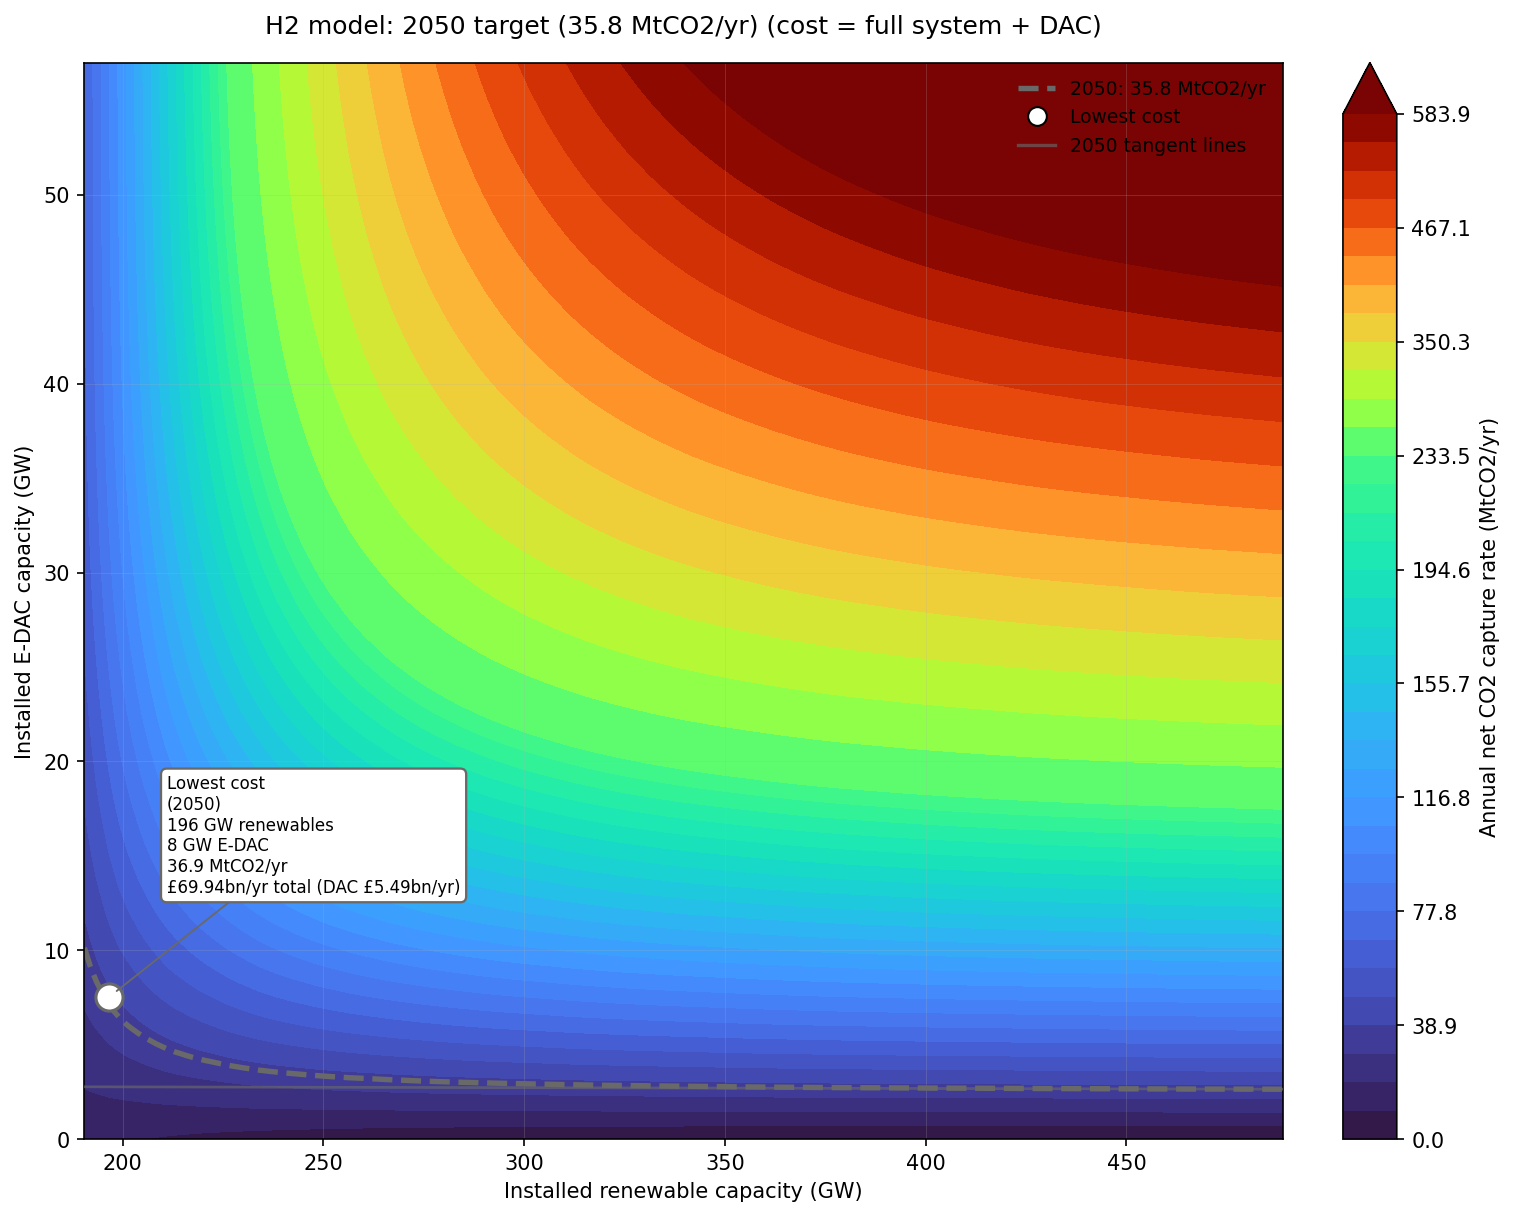

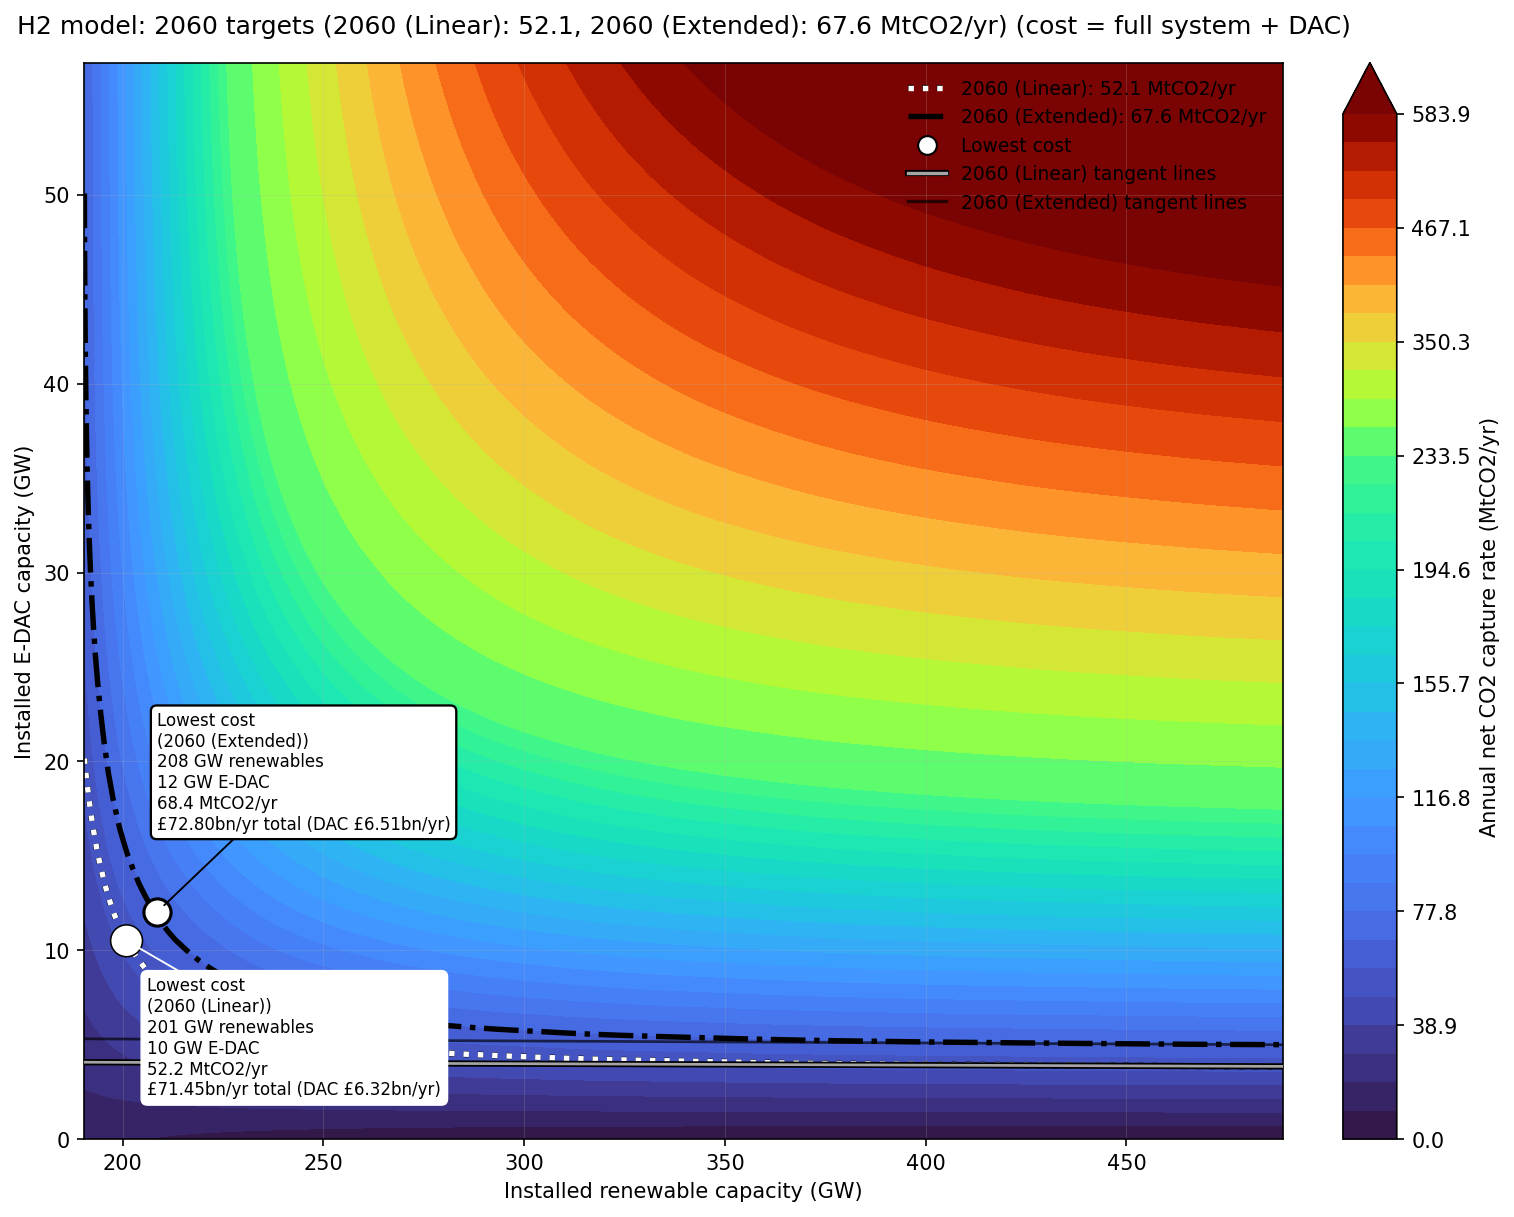

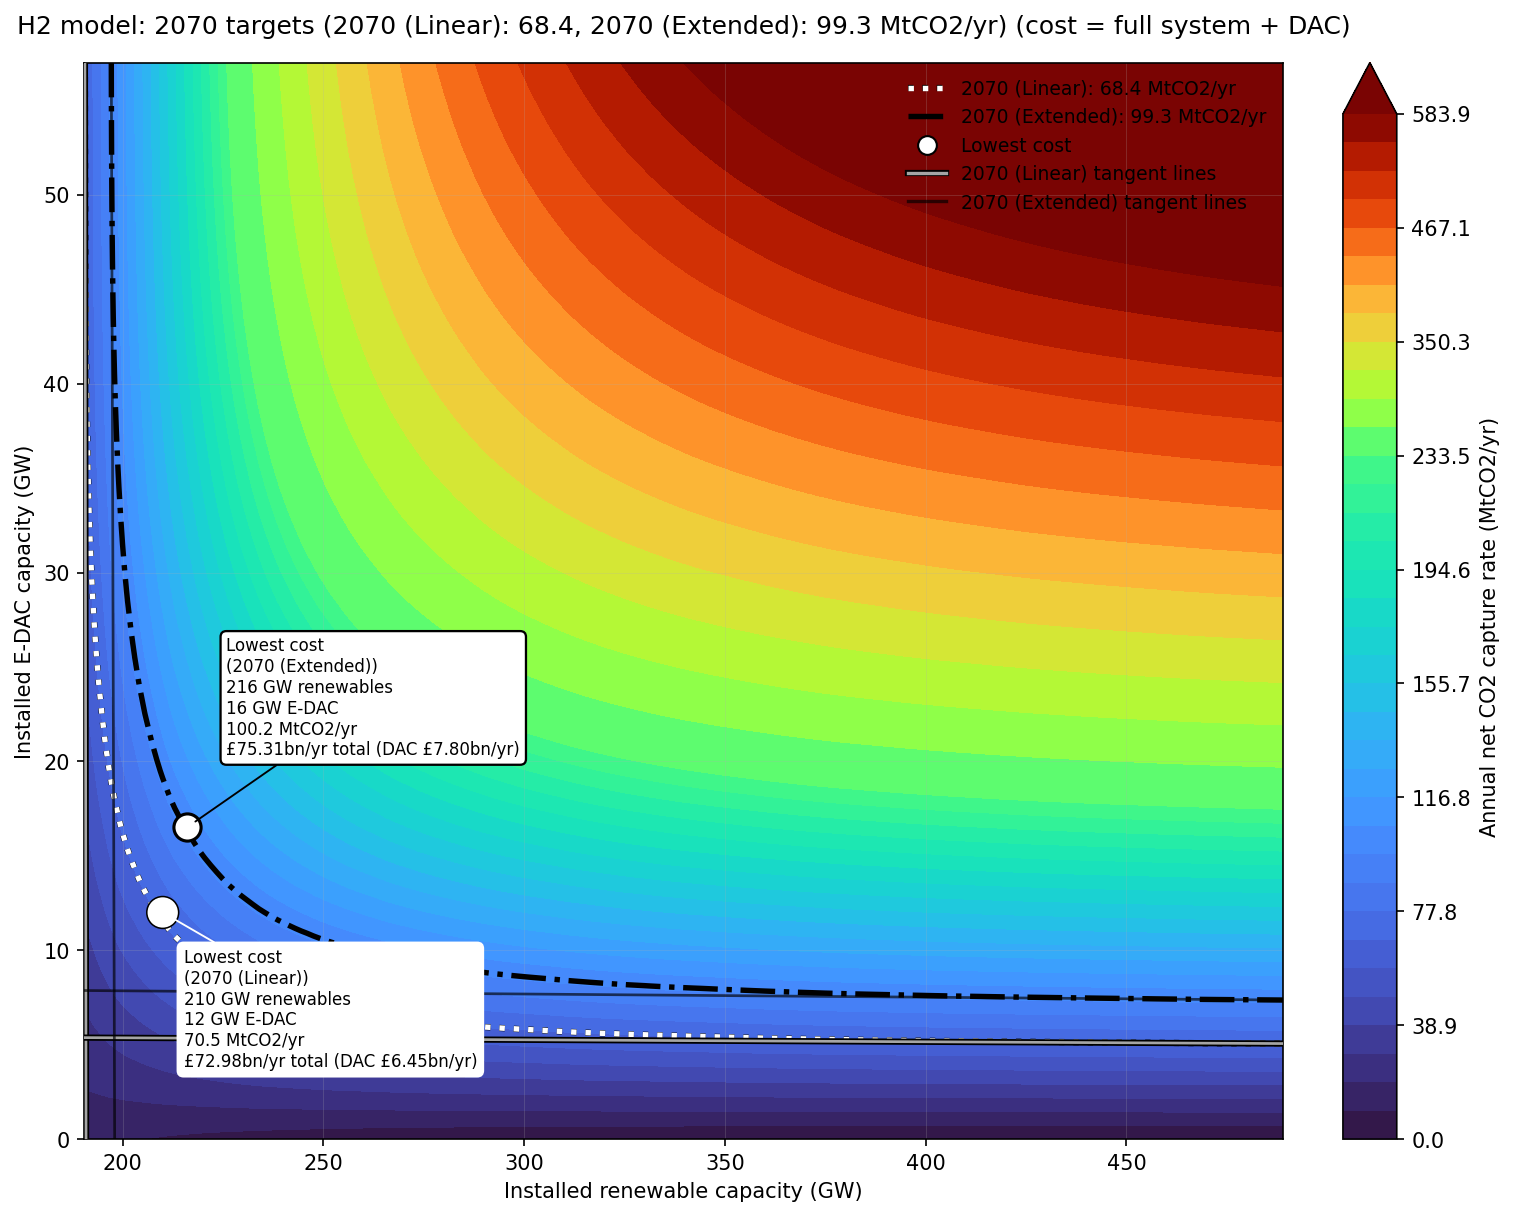

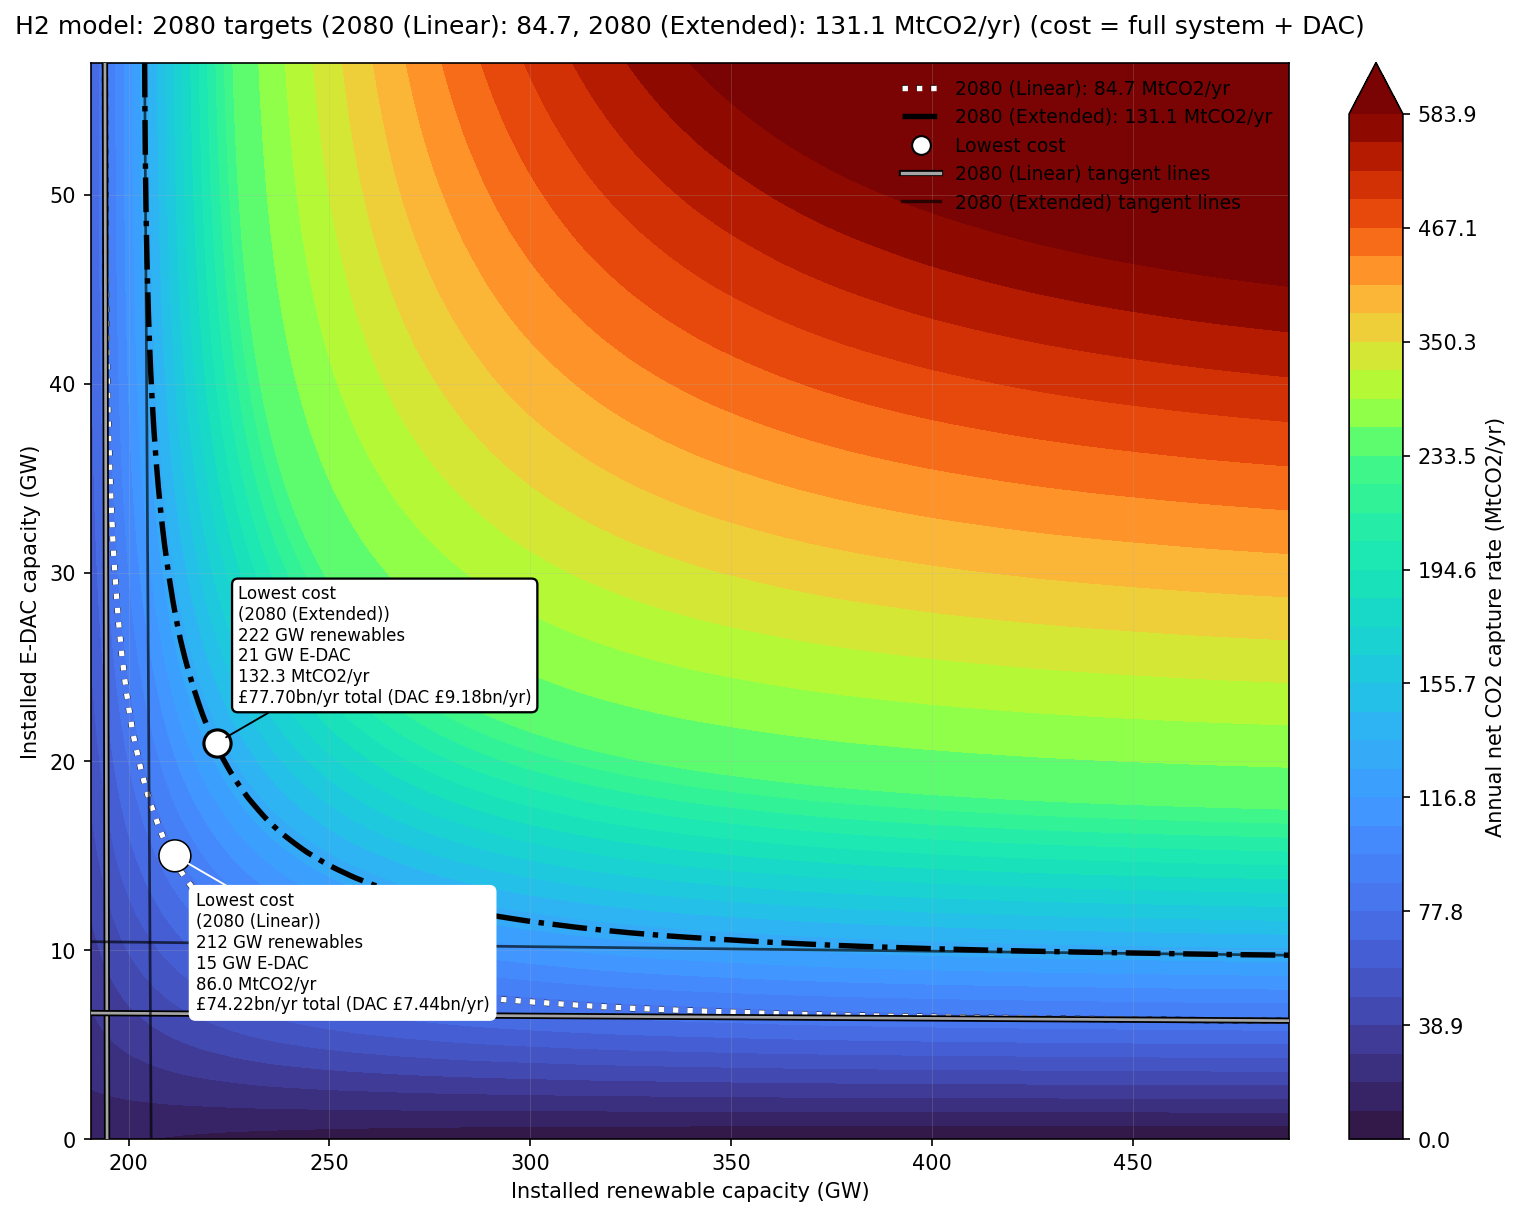

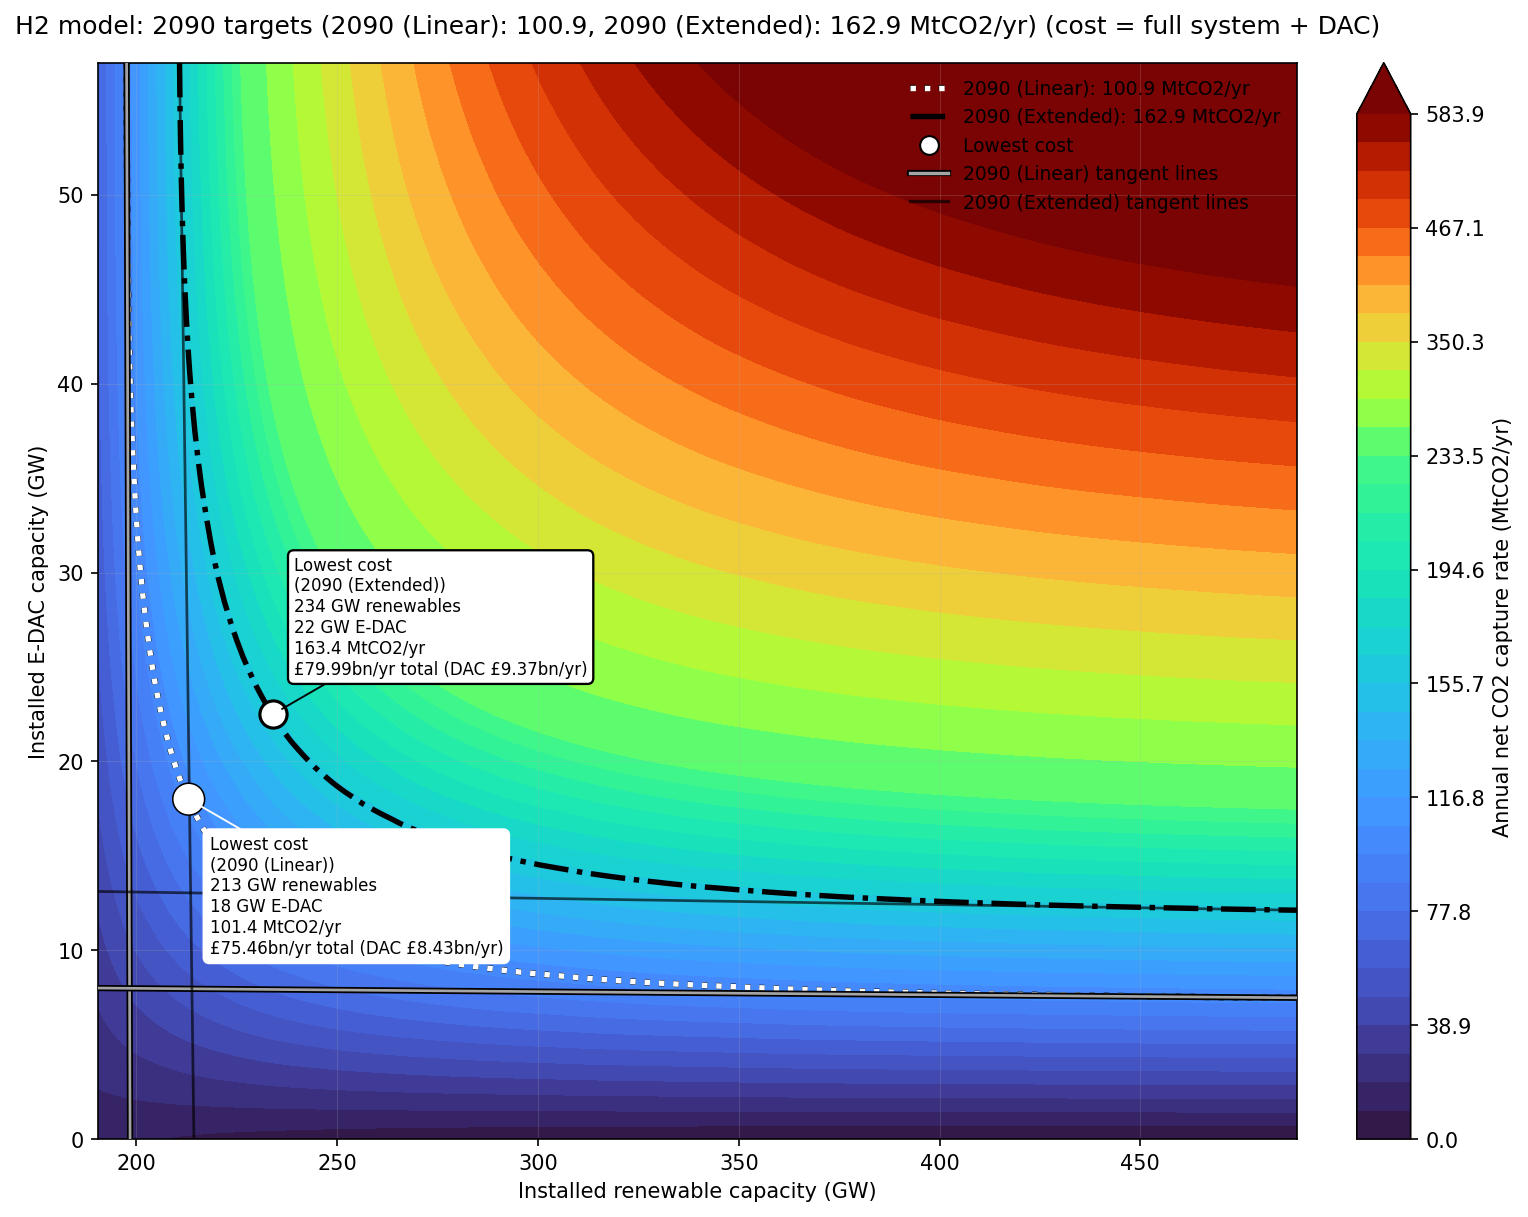

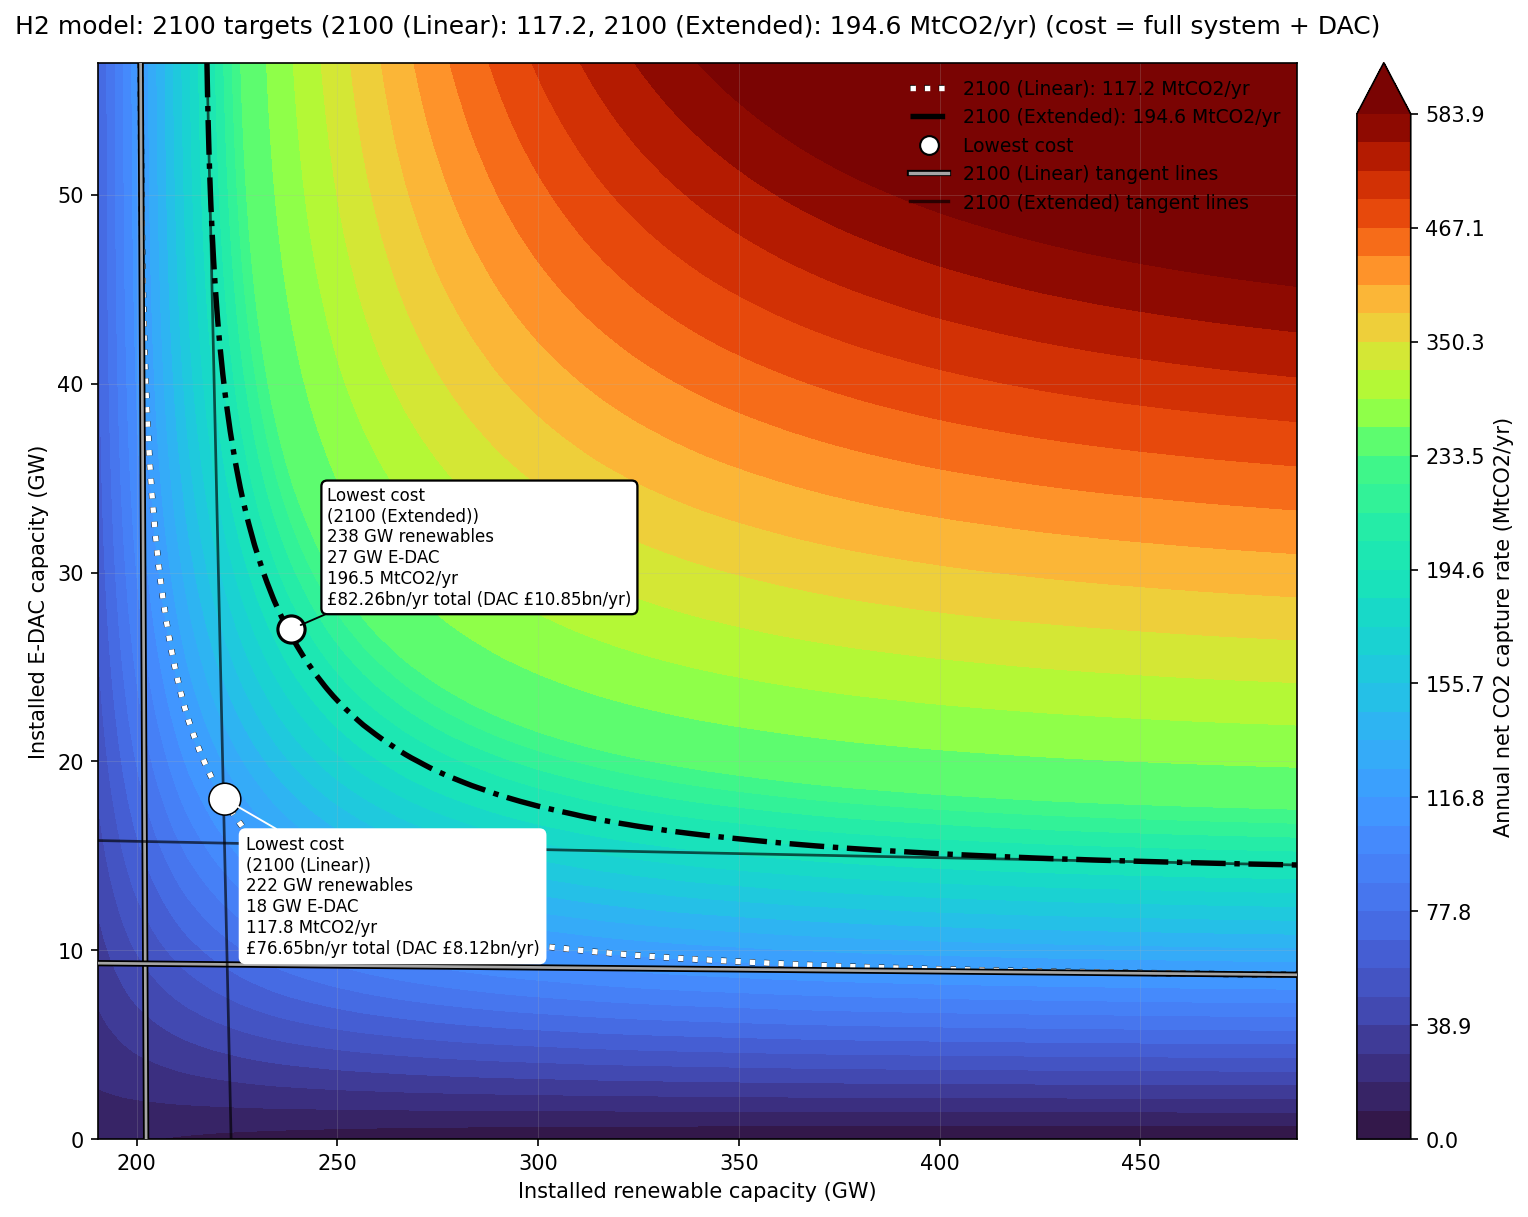

In [8]:
# One figure per year group: 2050 alone, then 2060-2100 each with blue and
# purple targets overlaid on the same axes (6 figures total). Each call's
# marker table (candidates_df) is kept in SUMMARY_TABLES, tagged by year, so
# the next cell can consolidate every plot's white-box contents into one table.
SUMMARY_TABLES = []
for year, target_specs in YEAR_GROUPS.items():
    plt.close("all")
    if len(target_specs) == 1:
        target_mt_per_yr = target_specs[0][0]
        title = (
            f"{year} target ({target_mt_per_yr:.1f} MtCO2/yr) "
            "(cost = full system + DAC)"
        )
    else:
        parts = ", ".join(f"{label}: {value:.1f}" for value, label, _, _ in target_specs)
        title = f"{year} targets ({parts} MtCO2/yr) (cost = full system + DAC)"
    _, _, candidates_df = plot_target_snapshot(target_specs, title)
    if candidates_df is not None:
        candidates_df = candidates_df.copy()
        candidates_df["year"] = year
        SUMMARY_TABLES.append(candidates_df)

In [9]:
# Consolidated table of every white-box marker across all 6 plots above:
# one row per (year, pathway, point type) -- 11 targets x 3 point types = 33
# rows -- sorted the same way the plots themselves are grouped (year, then
# blue before purple, then Lowest cost / Lowest renewables / Lowest E-DAC).
all_markers = pd.concat(SUMMARY_TABLES, ignore_index=True)


def _pathway(label: str) -> str:
    if "(Linear)" in label:
        return "Linear"
    if "(Extended)" in label:
        return "Extended"
    return "-"


all_markers["pathway"] = all_markers["target_label"].map(_pathway)

POINT_TYPE_ORDER = {"Lowest cost": 0, "Lowest renewables": 1, "Lowest E-DAC": 2}
PATHWAY_ORDER = {"-": 0, "Linear": 1, "Extended": 2}

all_markers["_point_order"] = all_markers["point_type"].map(POINT_TYPE_ORDER)
all_markers["_pathway_order"] = all_markers["pathway"].map(PATHWAY_ORDER)

summary_table = (
    all_markers.sort_values(["year", "_pathway_order", "_point_order"])
    .reset_index(drop=True)
    .assign(
        **{
            "Year": lambda d: d["year"],
            "Pathway": lambda d: d["pathway"],
            "Point type": lambda d: d["point_type"],
            "Renewables (GW)": lambda d: d["renewables_gw"].round(0).astype(int),
            "E-DAC (GW)": lambda d: d["e_dac_capacity_gw"].round(0).astype(int),
            "Annual capture (MtCO2/yr)": lambda d: d["metric_value"].round(1),
            "Total cost (£bn/yr)": lambda d: (d["total_cost_gbp_yr"] / 1e9).round(2),
            "DAC cost (£bn/yr)": lambda d: (d["dac_cost_gbp_yr"] / 1e9).round(2),
        }
    )[
        [
            "Year",
            "Pathway",
            "Point type",
            "Renewables (GW)",
            "E-DAC (GW)",
            "Annual capture (MtCO2/yr)",
            "Total cost (£bn/yr)",
            "DAC cost (£bn/yr)",
        ]
    ]
)

summary_table


,Year,Pathway,Point type,Renewables (GW),E-DAC (GW),Annual capture (MtCO2/yr),Total cost (£bn/yr),DAC cost (£bn/yr)
0,2050,-,Lowest cost,196,8,36.9,69.94,5.49
1,2050,-,Lowest renewables,190,10,35.8,70.45,6.87
2,2050,-,Lowest E-DAC,489,3,35.8,124.80,1.09
3,2060,Linear,Lowest cost,201,10,52.2,71.45,6.32
4,2060,Linear,Lowest renewables,190,20,52.1,73.61,10.03
5,2060,Linear,Lowest E-DAC,489,4,52.1,125.33,1.62
6,2060,Extended,Lowest cost,208,12,68.4,72.80,6.51
7,2060,Extended,Lowest renewables,190,50,67.6,84.15,20.57
8,2060,Extended,Lowest E-DAC,489,5,67.6,125.33,1.62
9,2070,Linear,Lowest cost,210,12,70.5,72.98,6.45


## Journal-friendlier alternatives to the 6 separate contour plots

Two more compact views of the same result, better suited to a paper's main
text than six full-page annotated contour maps:

1. **Trend-line view** -- the actual finding (how much renewable/E-DAC
   capacity the lowest-cost system needs, year by year, along each pathway)
   drawn directly as two line charts, rather than read off six separate maps.
2. **Small-multiples view** -- the same six contour maps as before, but
   condensed into one figure with a shared colour scale, axes and legend, in
   the compact annotation style a journal figure would actually use.

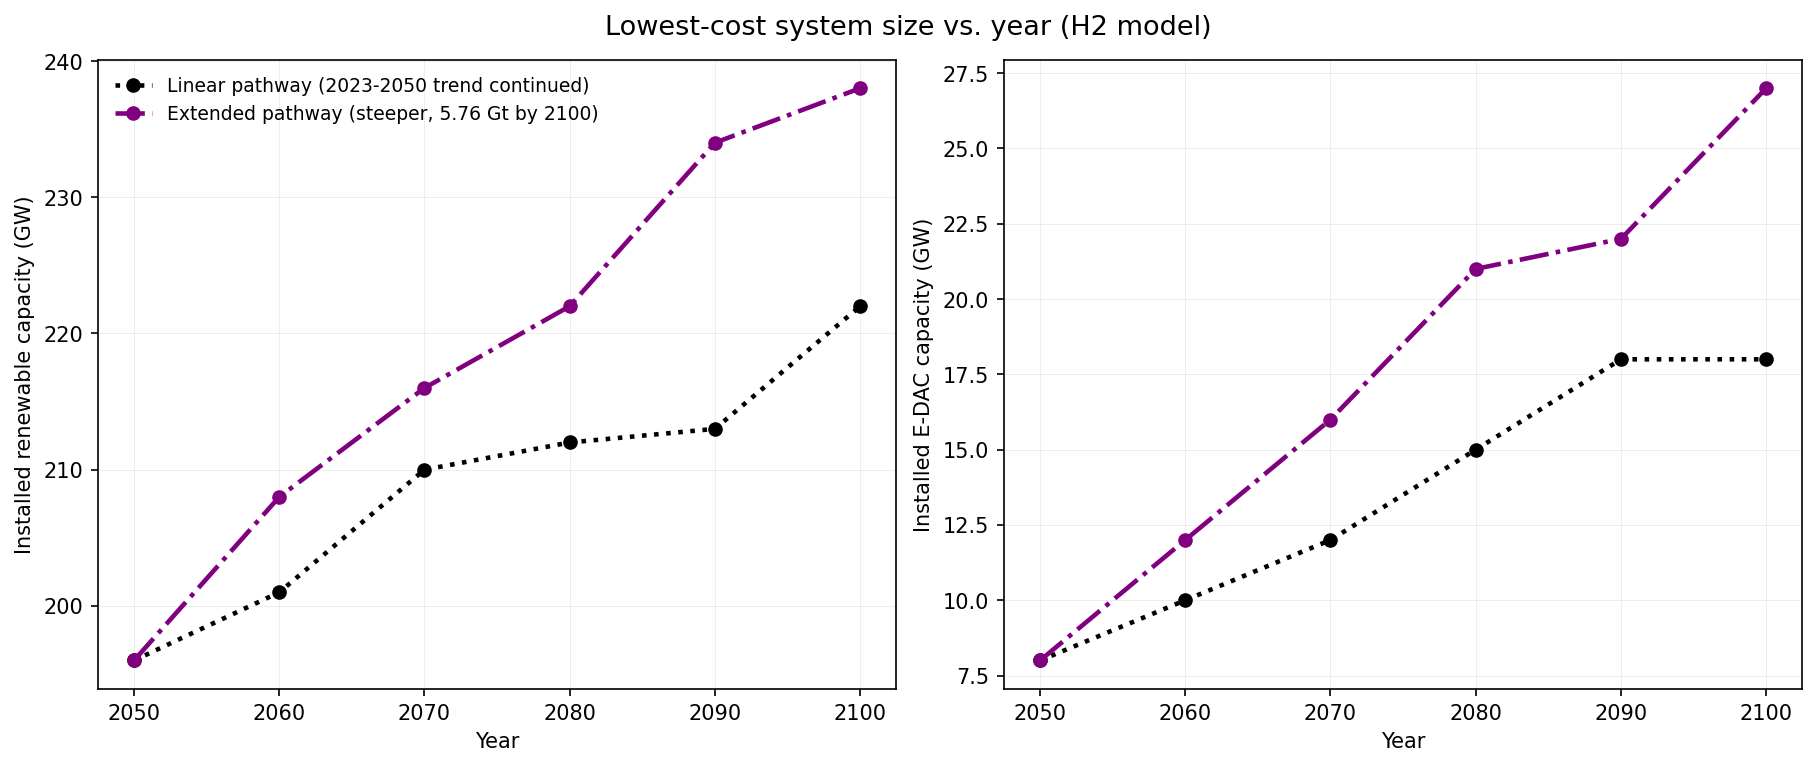

In [10]:
# Trend-line view: the lowest-cost system's required renewables and E-DAC
# capacity, year by year, for each pathway -- the actual finding, without
# needing to read it off six separate contour maps. 2050's single shared
# point is plotted as the common start of both lines.
lowest_cost = summary_table[summary_table["Point type"] == "Lowest cost"]

trend_rows = []
for year, group in lowest_cost.groupby("Year"):
    if len(group) == 1:
        row = group.iloc[0]
        for pathway in ("Linear", "Extended"):
            trend_rows.append(
                {
                    "Year": year,
                    "Pathway": pathway,
                    "Renewables (GW)": row["Renewables (GW)"],
                    "E-DAC (GW)": row["E-DAC (GW)"],
                }
            )
    else:
        for _, row in group.iterrows():
            trend_rows.append(
                {
                    "Year": year,
                    "Pathway": row["Pathway"],
                    "Renewables (GW)": row["Renewables (GW)"],
                    "E-DAC (GW)": row["E-DAC (GW)"],
                }
            )

trend_df = pd.DataFrame(trend_rows).sort_values(["Pathway", "Year"])

PATHWAY_STYLE = {
    "Linear": {"color": "black", "linestyle": ":", "label": "Linear pathway (2023-2050 trend continued)"},
    "Extended": {"color": "purple", "linestyle": "-.", "label": "Extended pathway (steeper, 5.76 Gt by 2100)"},
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")

for pathway, style in PATHWAY_STYLE.items():
    sub = trend_df[trend_df["Pathway"] == pathway]
    axes[0].plot(
        sub["Year"], sub["Renewables (GW)"], marker="o",
        color=style["color"], linestyle=style["linestyle"], linewidth=2.2, label=style["label"],
    )
    axes[1].plot(
        sub["Year"], sub["E-DAC (GW)"], marker="o",
        color=style["color"], linestyle=style["linestyle"], linewidth=2.2, label=style["label"],
    )

axes[0].set_ylabel("Installed renewable capacity (GW)")
axes[1].set_ylabel("Installed E-DAC capacity (GW)")
for ax in axes:
    ax.set_xlabel("Year")
    ax.set_xticks(SNAPSHOT_YEARS)
    ax.grid(True, alpha=0.25)

axes[0].legend(fontsize=9, loc="upper left")
fig.suptitle("Lowest-cost system size vs. year (H2 model)", fontsize=13)
plt.show()

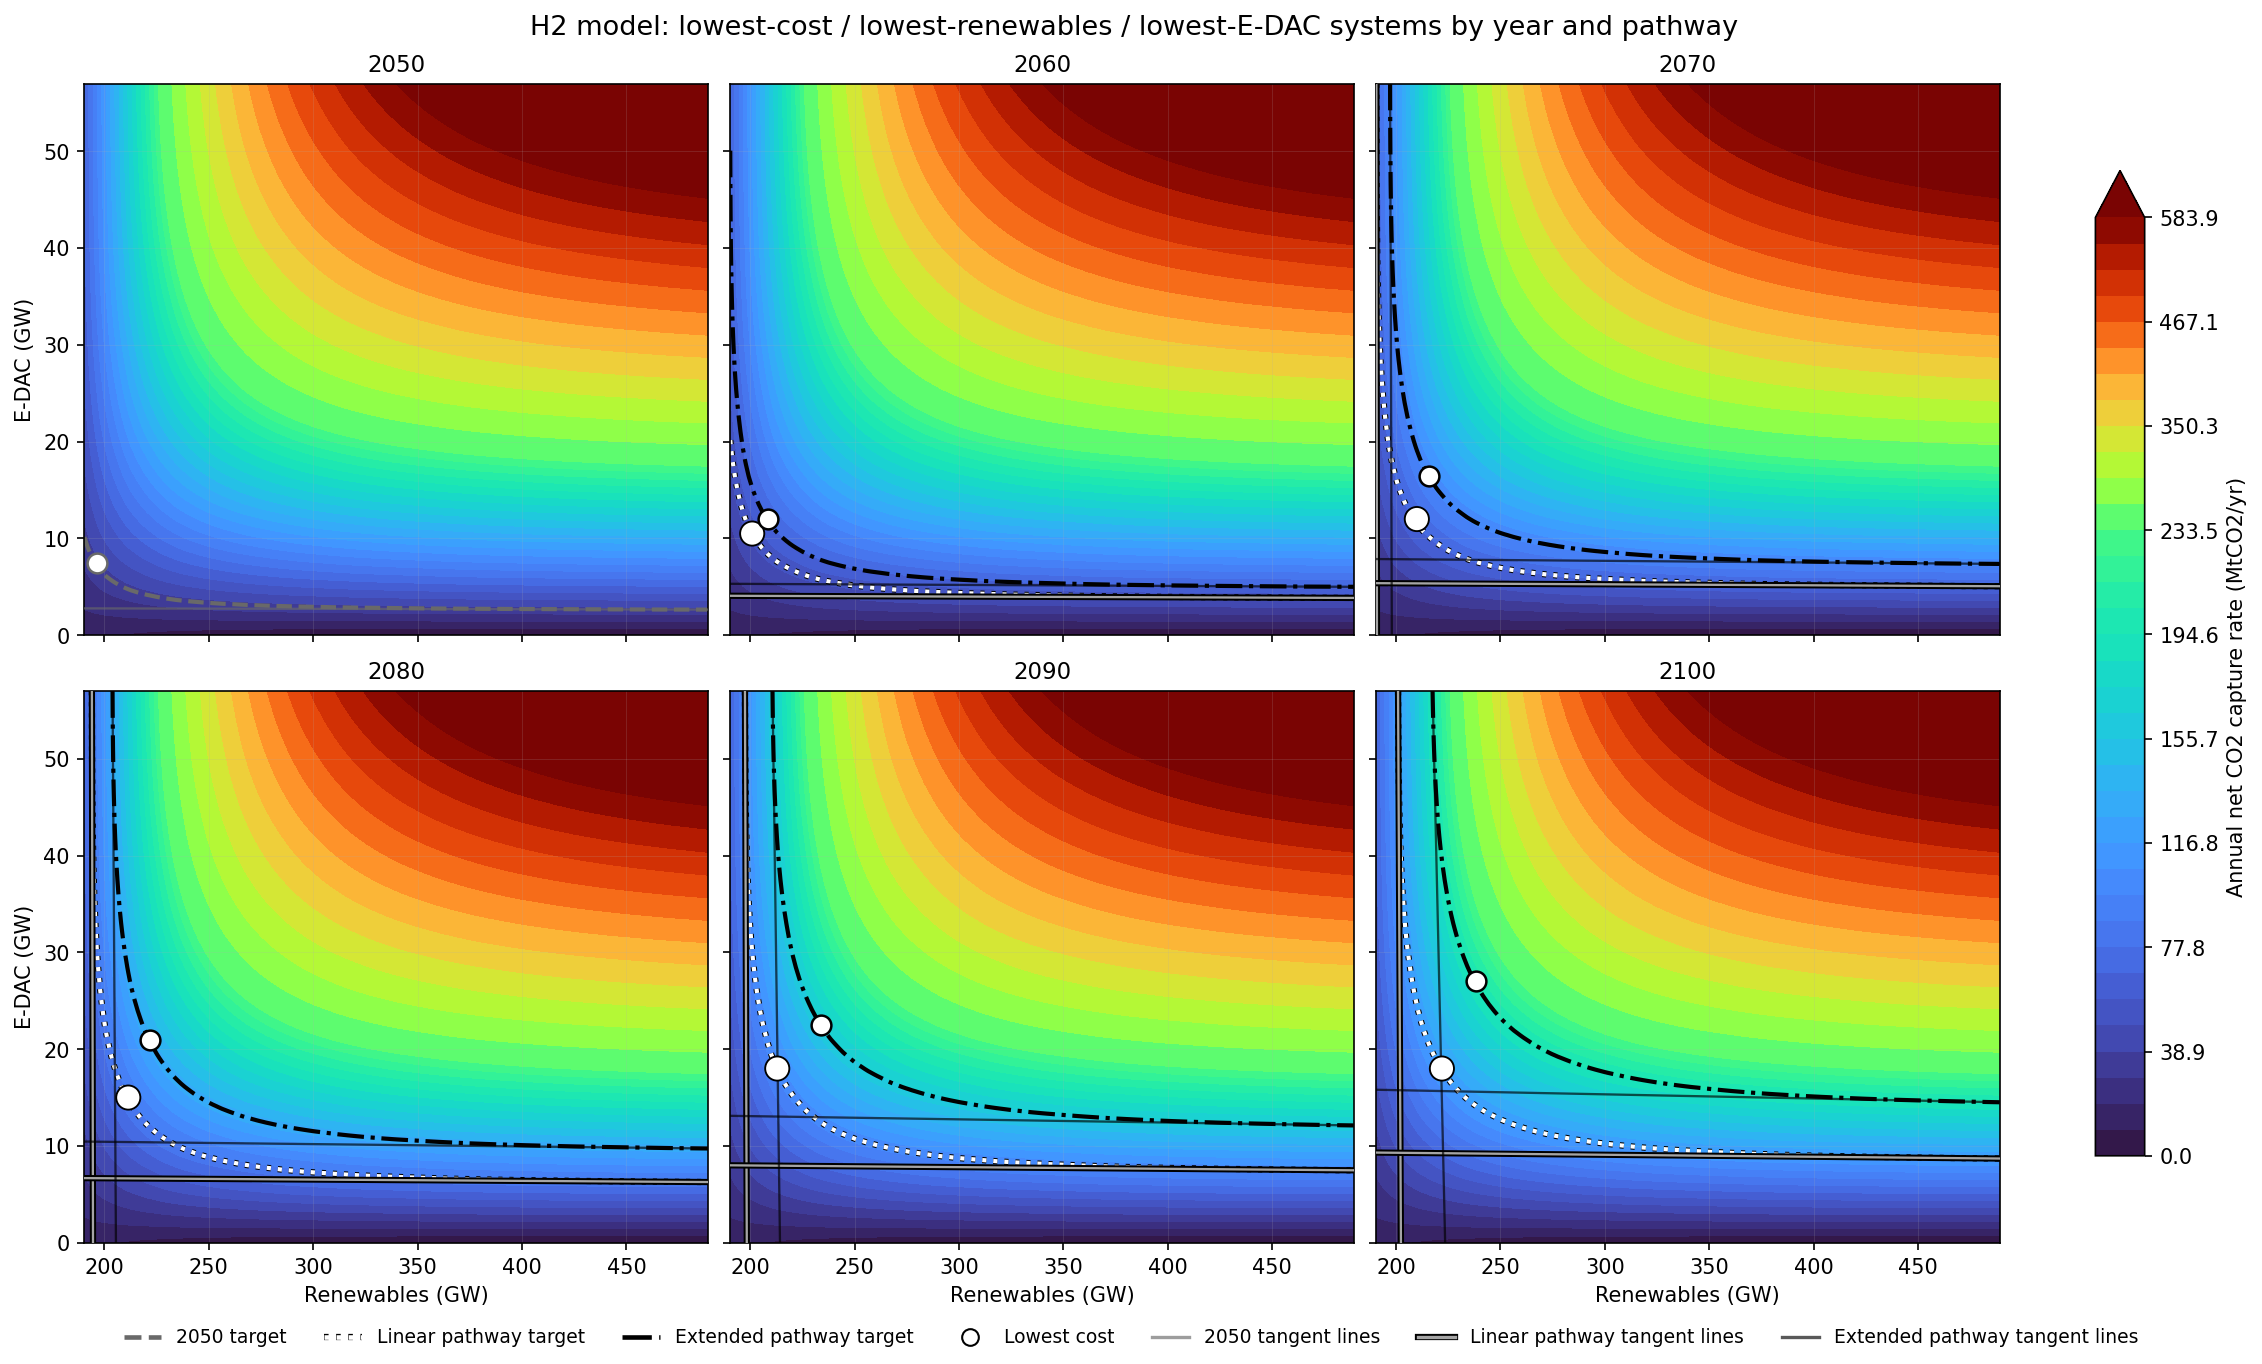

In [11]:
# Small-multiples view: the same 6 contour plots, condensed into one figure
# with a shared colour scale, shared axes, and one shared legend -- the
# compact form a journal figure would actually use, instead of six
# full-page plots with large per-point annotation boxes.
def _tangent_at_extreme(verts: np.ndarray, axis: int, n_neighbors: int = 3):
    """Point + local slope (dy/dx) at the vertex extreme along `axis` (0 =
    leftmost point, 1 = bottommost point), estimated from a small
    neighbourhood of the curve's own vertices around it.
    """
    i0 = int(np.argmin(verts[:, axis]))
    i_lo, i_hi = max(0, i0 - n_neighbors), min(len(verts) - 1, i0 + n_neighbors)
    x0, y0 = verts[i0, 0], verts[i0, 1]
    if i_hi == i_lo:
        return x0, y0, 0.0
    dx = verts[i_hi, 0] - verts[i_lo, 0]
    dy = verts[i_hi, 1] - verts[i_lo, 1]
    return x0, y0, (dy / dx if dx != 0 else np.inf)


fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True, layout="constrained")

contour_mappable = None
for ax, (year, target_specs) in zip(axes.ravel(), YEAR_GROUPS.items(), strict=False):
    contour_mappable = ax.contourf(GRID_X, GRID_Y, GRID_Z, levels=GLOBAL_COLOR_LEVELS, cmap=COLOR_CMAP, extend="max")
    ax.set_xlim(UNIVERSAL_XLIM)
    ax.set_ylim(UNIVERSAL_YLIM)

    for target_mt_per_yr, label, color, linestyle in target_specs:
        meeting_df = PLOT_DF[PLOT_DF[METRIC_COL] >= target_mt_per_yr]
        if meeting_df.empty:
            continue
        cs = ax.contour(GRID_X, GRID_Y, GRID_Z, levels=[target_mt_per_yr], colors=color, linewidths=2.0, linestyles=linestyle)
        cs.set_path_effects(_outline_effect(color))

        lowest_cost_row = meeting_df.sort_values(["total_cost_gbp_yr", "renewables_gw", "e_dac_capacity_gw"]).iloc[0]

        # Tangent lines to the target curve at its global leftmost and
        # bottommost vertices within the searched grid. Skipped at the
        # leftmost extreme when it sits exactly on the grid's own left edge
        # (GRID_X.min()) -- there the curve hasn't actually reached its true
        # leftmost point, the search just stopped, so the "tangent" would be
        # a grid-boundary artifact rather than a real local slope (this is
        # what happens for 2050 and 2060; later years' curves settle within
        # the grid).
        paths = cs.get_paths()
        if paths:
            verts = np.concatenate([p.vertices for p in paths])
            for axis in (0, 1):
                x0, y0, slope = _tangent_at_extreme(verts, axis)
                if axis == 0 and np.isclose(x0, GRID_X.min()):
                    continue
                if np.isfinite(slope):
                    x_line = np.array(UNIVERSAL_XLIM)
                    (tangent_line,) = ax.plot(x_line, y0 + slope * (x_line - x0), color=color, linewidth=1.1, alpha=0.65, zorder=6)
                    tangent_line.set_path_effects(_outline_effect(color))
                else:
                    tangent_line = ax.axvline(x0, color=color, linewidth=1.1, alpha=0.65, zorder=6)
                    tangent_line.set_path_effects(_outline_effect(color))

        marker = ax.scatter(
            lowest_cost_row["renewables_gw"], lowest_cost_row["e_dac_capacity_gw"],
            marker=POINT_TYPE_MARKER["Lowest cost"], facecolor=POINT_TYPE_FACECOLOR["Lowest cost"],
            edgecolor=color, s=90, linewidth=1.2, zorder=7,
        )
        marker.set_path_effects(_outline_effect(color))

    ax.set_title(str(year), fontsize=11)
    ax.grid(True, alpha=0.2)

for ax in axes[:, 0]:
    ax.set_ylabel("E-DAC (GW)")
for ax in axes[-1, :]:
    ax.set_xlabel("Renewables (GW)")

fig.colorbar(contour_mappable, ax=axes, label="Annual net CO2 capture rate (MtCO2/yr)", shrink=0.85)

# Tangent-line entries are colored per target group (dimgray for the single
# 2050 target, white/black for the Linear/Extended pathways) rather than a
# single hardcoded "gray" -- that gray previously didn't match any of the
# colors actually drawn on the charts. The 2050 target curve itself (dimgray
# dashed, drawn above via YEAR_GROUPS[2050]) also gets its own legend entry
# now, rather than only its tangent lines being named. White entries carry
# the same black outline (`_outline_effect`) as their on-chart lines/markers,
# since white alone would be invisible both against the colormap's light
# band and against this legend's white background.
legend_handles = [
    Line2D([0], [0], color="dimgray", linestyle="--", linewidth=2.2, label="2050 target"),
    Line2D([0], [0], color="white", linestyle=":", linewidth=2.2, label="Linear pathway target", path_effects=_outline_effect("white")),
    Line2D([0], [0], color="black", linestyle="-.", linewidth=2.2, label="Extended pathway target"),
    Line2D([0], [0], marker="o", linestyle="", markerfacecolor="white", markeredgecolor="black", markersize=8, label="Lowest cost"),
    Line2D([0], [0], color="dimgray", linestyle="-", alpha=0.65, linewidth=1.6, label="2050 limiting cases"),
    Line2D([0], [0], color="white", linestyle="-", alpha=0.65, linewidth=1.6, label="Linear pathway limiting cases", path_effects=_outline_effect("white")),
    Line2D([0], [0], color="black", linestyle="-", alpha=0.65, linewidth=1.6, label="Extended pathway limiting cases"),
]
fig.legend(handles=legend_handles, loc="outside lower center", ncol=7, fontsize=9)

fig.suptitle("Lowest-cost / lowest-renewables / lowest-E-DAC systems by year and pathway", fontsize=13)

from pathlib import Path

output_dir = Path.cwd()
if output_dir.name == "nbs":
    output_dir = output_dir.parent
output_dir = output_dir / "output"
output_dir.mkdir(exist_ok=True)
fig.savefig(output_dir / "removal_target_year_snapshots.pdf", bbox_inches="tight")

plt.show()

In [12]:
# Three per-pathway views of summary_table -- same rows/columns, just split
# by the existing "Pathway" column so each is readable on its own, with that
# now-constant column dropped (and "Year" also dropped for the 2050 table,
# since every row there is 2050).
from IPython.display import display

table_2050 = (
    summary_table[summary_table["Pathway"] == "-"]
    .drop(columns=["Year", "Pathway"])
    .reset_index(drop=True)
)
table_linear = (
    summary_table[summary_table["Pathway"] == "Linear"]
    .drop(columns=["Pathway"])
    .reset_index(drop=True)
)
table_extended = (
    summary_table[summary_table["Pathway"] == "Extended"]
    .drop(columns=["Pathway"])
    .reset_index(drop=True)
)

print("2050 target")
display(table_2050)
print("\nLinear pathway (2023-2050 trend continued)")
display(table_linear)
print("\nExtended pathway (steeper, 5.76 Gt by 2100)")
display(table_extended)

2050 target


,Point type,Renewables (GW),E-DAC (GW),Annual capture (MtCO2/yr),Total cost (£bn/yr),DAC cost (£bn/yr)
0,Lowest cost,196,8,36.9,69.94,5.49
1,Lowest renewables,190,10,35.8,70.45,6.87
2,Lowest E-DAC,489,3,35.8,124.80,1.09



Linear pathway (2023-2050 trend continued)


,Year,Point type,Renewables (GW),E-DAC (GW),Annual capture (MtCO2/yr),Total cost (£bn/yr),DAC cost (£bn/yr)
0,2060,Lowest cost,201,10,52.2,71.45,6.32
1,2060,Lowest renewables,190,20,52.1,73.61,10.03
2,2060,Lowest E-DAC,489,4,52.1,125.33,1.62
3,2070,Lowest cost,210,12,70.5,72.98,6.45
4,2070,Lowest renewables,191,57,68.4,86.78,23.21
5,2070,Lowest E-DAC,489,5,68.4,125.33,1.62
6,2080,Lowest cost,212,15,86.0,74.22,7.44
7,2080,Lowest renewables,194,57,84.7,87.05,23.04
8,2080,Lowest E-DAC,489,6,84.7,125.86,2.14
9,2090,Lowest cost,213,18,101.4,75.46,8.43



Extended pathway (steeper, 5.76 Gt by 2100)


,Year,Point type,Renewables (GW),E-DAC (GW),Annual capture (MtCO2/yr),Total cost (£bn/yr),DAC cost (£bn/yr)
0,2060,Lowest cost,208,12,68.4,72.80,6.51
1,2060,Lowest renewables,190,50,67.6,84.15,20.57
2,2060,Lowest E-DAC,489,5,67.6,125.33,1.62
3,2070,Lowest cost,216,16,100.2,75.31,7.80
4,2070,Lowest renewables,197,57,99.3,87.33,22.88
5,2070,Lowest E-DAC,489,7,99.3,126.38,2.67
6,2080,Lowest cost,222,21,132.3,77.70,9.18
7,2080,Lowest renewables,204,57,131.1,88.10,22.51
8,2080,Lowest E-DAC,489,10,131.1,126.91,3.20
9,2090,Lowest cost,234,22,163.4,79.99,9.37
